## CHAIN FLOW: Supply Chain Performance & Delivery Analytics

In [1]:
## Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


In [2]:
## Step 2: Load & Select 15 Columns

df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin-1')

cols = ['Order Id', 'order date (DateOrders)', 
        'shipping date (DateOrders)', 'Shipping Mode',
        'Delivery Status', 'Late_delivery_risk',
        'Days for shipping (real)', 
        'Days for shipment (scheduled)',
        'Order Status', 'Category Name', 
        'Product Name', 'Sales per customer',
        'Order Profit Per Order', 
        'Order Item Quantity', 'Market']

df = df[cols]
print("✅ Dataset loaded!")
print("Shape:", df.shape)
print(df.head(3))

✅ Dataset loaded!
Shape: (180519, 15)
   Order Id order date (DateOrders) shipping date (DateOrders)  \
0     77202         1/31/2018 22:56             2/3/2018 22:56   
1     75939         1/13/2018 12:27            1/18/2018 12:27   
2     75938         1/13/2018 12:06            1/17/2018 12:06   

    Shipping Mode   Delivery Status  Late_delivery_risk  \
0  Standard Class  Advance shipping                   0   
1  Standard Class     Late delivery                   1   
2  Standard Class  Shipping on time                   0   

   Days for shipping (real)  Days for shipment (scheduled) Order Status  \
0                         3                              4     COMPLETE   
1                         5                              4      PENDING   
2                         4                              4       CLOSED   

    Category Name  Product Name  Sales per customer  Order Profit Per Order  \
0  Sporting Goods  Smart watch           314.640015               91.250000   
1

In [3]:

##Step 3: Split into 2 Tables

# Table 1 - Orders & Delivery
orders = df[['Order Id', 'order date (DateOrders)',
             'shipping date (DateOrders)', 'Shipping Mode',
             'Delivery Status', 'Late_delivery_risk',
             'Days for shipping (real)',
             'Days for shipment (scheduled)',
             'Order Status', 'Market']].copy()

# Table 2 - Products & Financials
products = df[['Order Id', 'Category Name',
               'Product Name', 'Sales per customer',
               'Order Profit Per Order',
               'Order Item Quantity']].copy()

print('✅ Tables created!')
print('Orders table:', orders.shape)
print('Products table:', products.shape)

✅ Tables created!
Orders table: (180519, 10)
Products table: (180519, 6)


In [4]:
## Step 4: Data Cleaning

# Convert dates
orders['order date (DateOrders)'] = pd.to_datetime(
    orders['order date (DateOrders)'])
orders['shipping date (DateOrders)'] = pd.to_datetime(
    orders['shipping date (DateOrders)'])

# Feature Engineering
orders['Shipping_Delay'] = (
    orders['Days for shipping (real)'] - 
    orders['Days for shipment (scheduled)'])

print("✅ Cleaning done!")
print("Missing values - Orders:")
print(orders.isnull().sum())
print("Missing values - Products:")
print(products.isnull().sum())

✅ Cleaning done!
Missing values - Orders:
Order Id                         0
order date (DateOrders)          0
shipping date (DateOrders)       0
Shipping Mode                    0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Order Status                     0
Market                           0
Shipping_Delay                   0
dtype: int64
Missing values - Products:
Order Id                  0
Category Name             0
Product Name              0
Sales per customer        0
Order Profit Per Order    0
Order Item Quantity       0
dtype: int64


In [5]:
## Step 5: Merge Tables
df_merged = pd.merge(orders, products, 
                     on='Order Id', how='inner')
print('✅ Tables merged!')
print('Merged shape:', df_merged.shape)
print(df_merged.head(3))

✅ Tables merged!
Merged shape: (639309, 16)
   Order Id order date (DateOrders) shipping date (DateOrders)  \
0     77202     2018-01-31 22:56:00        2018-02-03 22:56:00   
1     75939     2018-01-13 12:27:00        2018-01-18 12:27:00   
2     75938     2018-01-13 12:06:00        2018-01-17 12:06:00   

    Shipping Mode   Delivery Status  Late_delivery_risk  \
0  Standard Class  Advance shipping                   0   
1  Standard Class     Late delivery                   1   
2  Standard Class  Shipping on time                   0   

   Days for shipping (real)  Days for shipment (scheduled) Order Status  \
0                         3                              4     COMPLETE   
1                         5                              4      PENDING   
2                         4                              4       CLOSED   

         Market  Shipping_Delay   Category Name  Product Name  \
0  Pacific Asia              -1  Sporting Goods  Smart watch    
1  Pacific Asia        

In [6]:
## Step 6: Group By Analysis

print("=== Revenue by Market ===")
print(df_merged.groupby('Market')
      ['Sales per customer'].sum()
      .sort_values(ascending=False).round(2))

print()
print("=== Late Delivery by Shipping Mode ===")
print(df_merged.groupby('Shipping Mode')
      ['Late_delivery_risk'].mean()
      .sort_values(ascending=False).round(3))

print()
print("=== Top 10 Categories by Revenue ===")
print(df_merged.groupby('Category Name')
      ['Sales per customer'].sum()
      .sort_values(ascending=False).head(10).round(2))

=== Revenue by Market ===
Market
LATAM           33915213.63
Europe          32876063.77
Pacific Asia    24136675.83
USCA            16712744.14
Africa           7563975.92
Name: Sales per customer, dtype: float64

=== Late Delivery by Shipping Mode ===
Shipping Mode
First Class       0.954
Second Class      0.765
Same Day          0.458
Standard Class    0.381
Name: Late_delivery_risk, dtype: float64

=== Top 10 Categories by Revenue ===
Category Name
Fishing                 22803387.03
Cleats                  14550711.07
Camping & Hiking        13582805.73
Cardio Equipment        12133248.45
Women's Apparel         10380456.00
Water Sports            10239826.53
Men's Footwear           9544337.54
Indoor/Outdoor Games     9533607.48
Shop By Sport            4297092.15
Electronics              1232580.64
Name: Sales per customer, dtype: float64


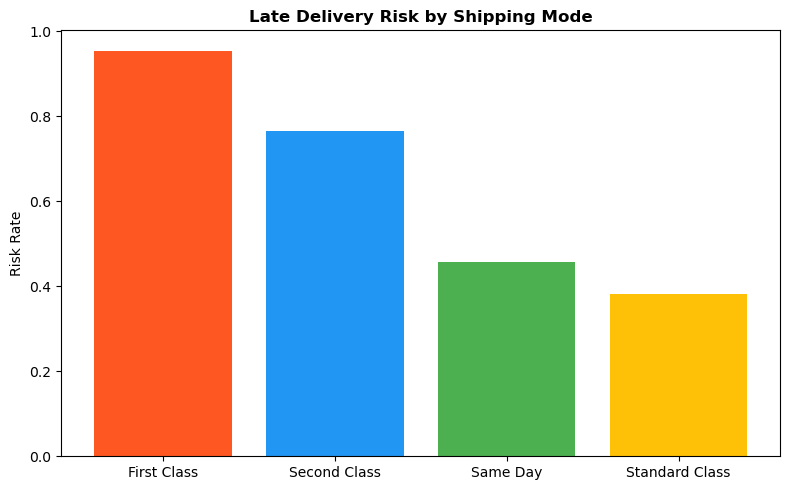

✅ Chart 1 saved!


In [8]:
# Chart 1 - Late Delivery Risk by Shipping Mode

late = df_merged.groupby('Shipping Mode')['Late_delivery_risk'].mean().sort_values(ascending=False)
plt.figure(figsize=(8,5))
plt.bar(late.index, late.values, color=['#FF5722','#2196F3','#4CAF50','#FFC107'])
plt.title('Late Delivery Risk by Shipping Mode', fontweight='bold')
plt.ylabel('Risk Rate')
plt.tight_layout()
plt.savefig('chart1_late_delivery.png', dpi=150)
plt.show()
print("✅ Chart 1 saved!")


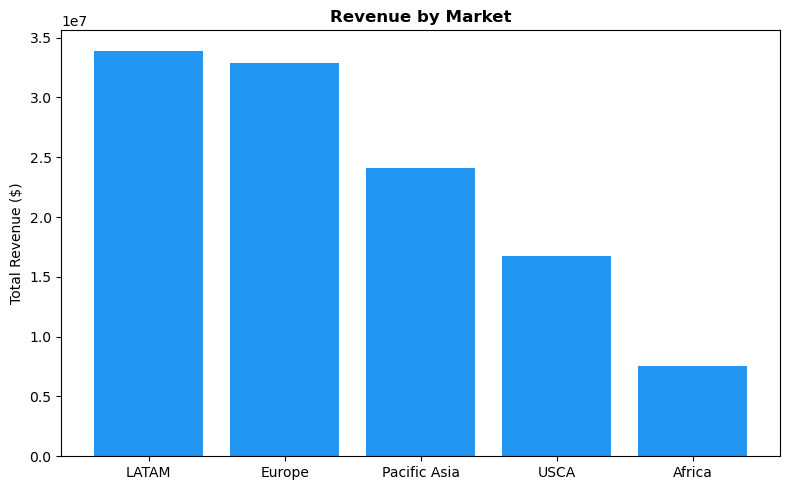

✅ Chart 2 saved!


In [9]:
# Chart 2 - Revenue by Market

market = df_merged.groupby('Market')['Sales per customer'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
plt.bar(market.index, market.values, color='#2196F3')
plt.title('Revenue by Market', fontweight='bold')
plt.ylabel('Total Revenue ($)')
plt.tight_layout()
plt.savefig('chart2_revenue_market.png', dpi=150)
plt.show()
print("✅ Chart 2 saved!")

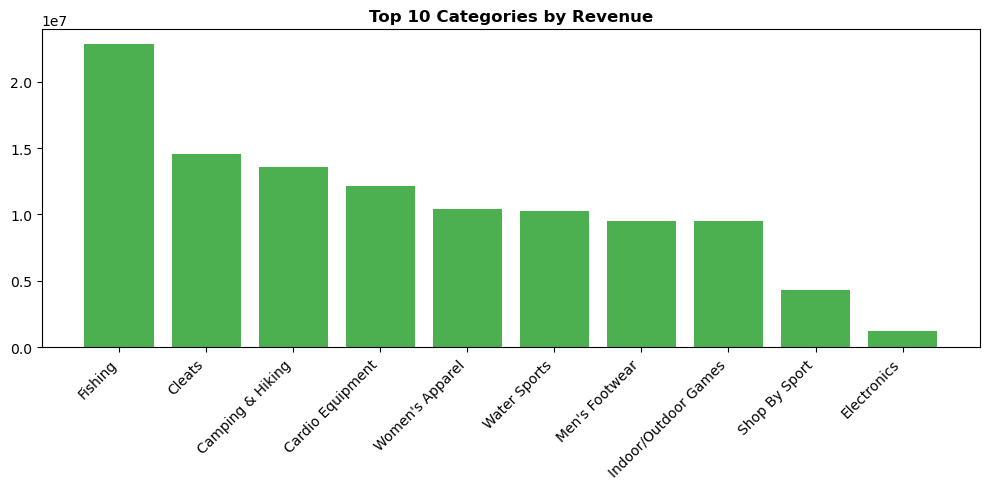

✅ Chart 3 saved!


In [10]:
# Chart 3 - Top 10 Categories by Revenue
cats = df_merged.groupby('Category Name')['Sales per customer'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
plt.bar(cats.index, cats.values, color='#4CAF50')
plt.title('Top 10 Categories by Revenue', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('chart3_top_categories.png', dpi=150)
plt.show()
print("✅ Chart 3 saved!")

In [11]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook()

# Sheet 1 - Summary
ws1 = wb.active
ws1.title = 'Summary'
ws1['A1'] = 'ChainFlow: Supply Chain Performance & Delivery Analytics'
ws1['A1'].font = Font(bold=True, size=14)
ws1.append([])
ws1.append(['Metric', 'Value'])
ws1.append(['Total Orders', 180519])
ws1.append(['Total Markets', 5])
ws1.append(['Top Market', 'LATAM'])
ws1.append(['Top Category', 'Fishing'])
ws1.append(['Highest Late Delivery Risk', 'First Class'])
ws1.column_dimensions['A'].width = 35
ws1.column_dimensions['B'].width = 25

# Sheet 2 - Orders
ws2 = wb.create_sheet('Orders')
ws2.append(list(orders.columns))
for _, row in orders.head(200).iterrows():
    ws2.append(list(row))

# Sheet 3 - Products
ws3 = wb.create_sheet('Products')
ws3.append(list(products.columns))
for _, row in products.head(200).iterrows():
    ws3.append(list(row))

wb.save('supply_chain_report.xlsx')
print("Excel report saved!")

Excel report saved!
